# OCA en un solo cuaderno

Este cuaderno implementa de principio a fin la técnica de agrupamiento basada en optimización (Optimization-based Clustering Approach, OCA) de Rodríguez-Pretelín, Nowak y Morales-Casique (2022), *Optimization-based clustering of random fields for computationally efficient and goal-oriented uncertainty quantification*, Advances in Water Resources, [doi 10.1016/j.advwatres.2022.104146](https://doi.org/10.1016/j.advwatres.2022.104146).

Es la traducción a Python del código MATLAB original del paper, el script `Clusterizar_paper_4.m` y la implementación de OMOPSO de Abelardo Rodríguez-Pretelín. Cada función conserva su nombre de MATLAB.

**La idea en una frase.** Simular miles de realizaciones de conductividad hidráulica para delinear una zona de protección de pozo (WHPA) es caro. La OCA elige un subconjunto pequeño de realizaciones, por ejemplo 10, cuyo mapa probabilístico reproduce las delineaciones del ensamble completo en los isopercentiles del 10, 50 y 90 por ciento. Con esas 10 realizaciones se pueden correr después los modelos caros, como el transitorio.

**Ruta del cuaderno**

1. Generar el ensamble Monte Carlo con `rrwpt` (campos de ln K y zonas de captura estacionarias).
2. Cerrar cada zona de captura con su envolvente convexa y construir el mapa probabilístico de referencia.
3. Extraer tres características por realización.
4. Definir la función de costo de la OCA.
5. Implementar OMOPSO función por función.
6. Correr la optimización, elegir la solución de mejor compromiso y verificar la delineación.

## 0. Instalación

Necesitas Python 3.10 o superior y el paquete `rrwpt`, que es el simulador de flujo y trazado de partículas del laboratorio.

```
pip install numpy scipy matplotlib
pip install git+https://github.com/abelardo1685/rrwpt.git
```

In [1]:
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
from scipy.spatial.distance import cdist

import rrwpt
from rrwpt import config, pipeline, geostat, fem
print("rrwpt", getattr(rrwpt, "__version__", ""))

rrwpt 0.2.0.dev0


## 1. Ensamble Monte Carlo con rrwpt

El paper usa un dominio de 5 250 m por lado con 2 000 a 4 000 realizaciones, lo que toma horas. Aquí usamos una versión reducida en 2D, con una malla de 100 por 100 celdas de 30 m, tres pozos y 200 realizaciones, para que todo corra en pocos minutos en una laptop. La estructura del método es la misma.

Cada realización tiene un campo de ln K condicionado a 10 mediciones de una verdad sintética y un modelo de flujo estacionario con trazado inverso de partículas. El resultado es un mapa binario de la zona de captura (1 si la celda envía agua a algún pozo antes del tiempo crítico).

Los resultados se guardan en `datos_oca.npz`. Si el archivo existe se leen de ahí y no se vuelve a simular.

In [2]:
# Parámetros del ensamble reducido
N_REAL   = 200      # número de realizaciones (en el paper tam = 4000)
N_CELDAS = 100      # celdas por lado
DX       = 30.0     # tamaño de celda [m]
T_CRIT   = 90.0     # tiempo crítico [d]
SEMILLA  = 2022
ARCHIVO  = Path("datos_oca.npz")

opciones = {
    "Two_D": 1, "n_pts_x": N_CELDAS, "n_pts_y": N_CELDAS, "d_pts_x": DX, "d_pts_y": DX,
    "inP": np.array([0.80, 0.50, 0.70]),                         # pozo principal (fracción x, y)
    "Ex_pump": 1, "Ex_inP": np.array([[0.80, 0.42], [0.80, 0.58]]),  # dos pozos más
    "het": 1,                                                    # campo heterogéneo
    "stru.muA": -6.0, "stru.muE": -6.0, "stru.variA": 1.0, "stru.variE": 1.0,   # media y varianza de ln K
    "stru.kapA": 0.9, "stru.kapE": 0.9,                          # suavidad de Matérn
    "stru.intexA": 500.0, "stru.intexE": 500.0, "stru.inteyA": 600.0, "stru.inteyE": 600.0,  # longitudes de correlación [m]
    "crit.t_crit": T_CRIT,
    "cond.Kflag": 1, "cond.n_cond": 10, "cond.seed_field": 1, "cond.seed_obs": 2, "cond.r_K": 0.01,  # condicionamiento
    "tim.tend": 2 * T_CRIT, "tim.deltQS": T_CRIT,                # un solo paso: flujo estacionario
    "trns.npartic_QS": 500,                                      # partículas por pozo
}
fem.HAS_PYAMG = False   # en mallas pequeñas la factorización directa es suficiente

def simular_ensamble():
    ctrl = config.make_ctrl(**opciones)
    grid, flowpar, model, ctrl = pipeline.setup(ctrl, np.random.default_rng(SEMILLA))
    K, A = [], []
    t0 = time.time()
    for i in range(N_REAL):
        yk = geostat.uncsim_kfield(ctrl, model, grid, rng=np.random.default_rng([SEMILLA, i, 0]))
        fem.clear_solver_cache()
        res = pipeline.run_realization(ctrl, grid, model, flowpar, rng=np.random.default_rng([SEMILLA, i, 1]),
                                       verbose=False, yk=yk)
        K.append(yk.reshape((N_CELDAS, N_CELDAS), order="F").astype(np.float32))
        A.append(pipeline.prob_map_2d(res, grid) > 0)
        if (i + 1) % 25 == 0:
            print(f"  {i + 1}/{N_REAL} realizaciones, {time.time() - t0:.0f} s")
    return np.array(K), np.array(A)

if ARCHIVO.exists():
    z = np.load(ARCHIVO); K_field, Prob_map = z["K_field"], z["Prob_map"]
    print("Ensamble leído de", ARCHIVO)
else:
    K_field, Prob_map = simular_ensamble()
    np.savez_compressed(ARCHIVO, K_field=K_field, Prob_map=Prob_map)
tam, lado_y, lado_x = Prob_map.shape
print("ln K", K_field.shape, "  zonas de captura", Prob_map.shape)

Ensamble leído de datos_oca.npz
ln K (200, 100, 100)   zonas de captura (200, 101, 101)


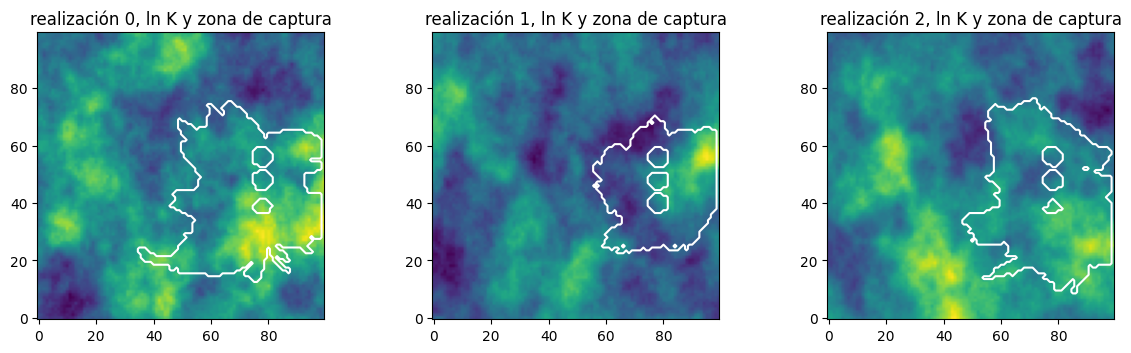

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for j, i in enumerate([0, 1, 2]):
    ax[j].imshow(K_field[i], cmap="viridis", origin="lower")
    ax[j].contour(Prob_map[i, :-1, :-1], levels=[0.5], colors="w")
    ax[j].set_title(f"realización {i}, ln K y zona de captura")
plt.tight_layout(); plt.show()

## 2. Envolvente convexa y mapa probabilístico de referencia

Igual que en `Clusterizar_paper_4.m`, cada zona de captura se cierra con su envolvente convexa (convex hull). Esto elimina los huecos que deja el ruido del trazado de partículas. El resultado de cada realización es un vector binario `MC_Steady[i]`.

El parámetro `FILAS_EN_CERO` pone en cero las primeras filas del mapa, como `BW(1:10,:)=0` en el script.

El mapa probabilístico de referencia es la suma de las envolventes dividida entre su máximo, como en MATLAB (`MC_avmap_st = sum(MC_Steady)/max(...)`). Si alguna celda está en la zona de todas las realizaciones, eso es lo mismo que el promedio. Las delineaciones de referencia son las celdas con probabilidad de al menos 0.1, 0.5 y 0.9.

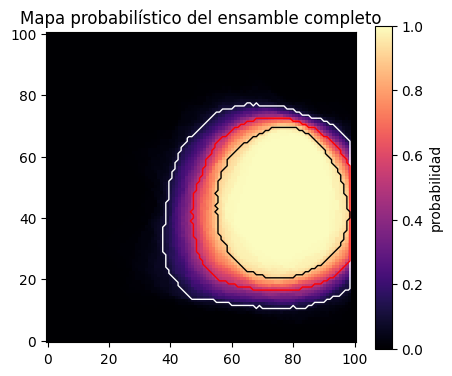

In [4]:
FILAS_EN_CERO = 0
cc, rr = np.meshgrid(np.arange(lado_x), np.arange(lado_y))
puntos = np.column_stack([cc.ravel(), rr.ravel()]).astype(float)

def envolvente_convexa(BW):
    # Equivale a convhull + inpolygon de MATLAB. inpolygon incluye la frontera, por eso la tolerancia 1e-9.
    BW = BW.copy(); BW[:FILAS_EN_CERO, :] = 0
    row, col = np.nonzero(BW)
    if row.size < 3:
        return BW.ravel().astype(np.uint8)
    hull = ConvexHull(np.column_stack([col, row]).astype(float))
    dentro = np.all(puntos @ hull.equations[:, :2].T + hull.equations[:, 2] <= 1e-9, axis=1)
    return dentro.astype(np.uint8)

MC_Steady = np.stack([envolvente_convexa(Prob_map[i]) for i in range(tam)])   # (tam, lado_y*lado_x)

MC_avmap_st = MC_Steady.sum(axis=0) / MC_Steady.sum(axis=0).max()
map_A_10_st = MC_avmap_st >= 0.1
map_A_50_st = MC_avmap_st >= 0.5
map_A_90_st = MC_avmap_st >= 0.9

plt.figure(figsize=(5, 4.2))
plt.imshow(MC_avmap_st.reshape(lado_y, lado_x), origin="lower", cmap="magma"); plt.colorbar(label="probabilidad")
for m, c in [(map_A_10_st, "w"), (map_A_50_st, "r"), (map_A_90_st, "k")]:
    plt.contour(m.reshape(lado_y, lado_x), levels=[0.5], colors=c, linewidths=1)
plt.title("Mapa probabilístico del ensamble completo"); plt.show()

## 3. Extracción de características

Cada realización se resume con tres números, todos normalizados entre su valor máximo.

* `K_distance`, la distancia euclidiana entre el campo ln K de la realización y el campo promedio del ensamble.
* `A_distance`, el área de la zona de captura (número de celdas dentro de la envolvente). En MATLAB se llama distancia aunque es un área.
* `Amean_distance`, la distancia euclidiana entre la zona de captura de la realización y el mapa probabilístico promedio.

La matriz `X` de tamaño `tam` por 3 es el espacio donde vuela el enjambre de OMOPSO.

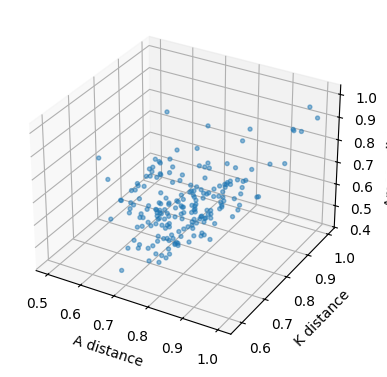

In [5]:
K_plano = K_field.reshape(tam, -1).astype(np.float64)
K_mean_st = K_plano.mean(axis=0)
K_distance_st = np.linalg.norm(K_plano - K_mean_st, axis=1)
K_distance_st /= K_distance_st.max()

A_distance_st = MC_Steady.sum(axis=1).astype(np.float64)
A_distance_st /= A_distance_st.max()

Amean_distance_st = np.linalg.norm(MC_Steady - MC_avmap_st, axis=1)
Amean_distance_st /= Amean_distance_st.max()

X = np.column_stack([K_distance_st, A_distance_st, Amean_distance_st])

ax = plt.figure(figsize=(5, 4.5)).add_subplot(projection="3d")
ax.scatter(A_distance_st, K_distance_st, Amean_distance_st, s=8, alpha=0.5)
ax.set_xlabel("A distance"); ax.set_ylabel("K distance"); ax.set_zlabel("Amean distance"); plt.show()

## 4. Función de costo de la OCA

Una solución es una matriz de `k` posiciones en el espacio `X` (aquí `k = 10`). Cada posición se ancla a la realización real más cercana, que funciona como medoide. Se promedian las envolventes de esos `k` medoides con peso igual, se delinea el mapa resultante en 0.1, 0.5 y 0.9 y se compara celda por celda con la delineación de referencia.

El costo de cada nivel es el número de celdas en que ambas delineaciones no coinciden. En MATLAB se suma el mapa de referencia (valor 2) con el del subconjunto (valor 1). El valor 2 significa que la celda solo está en la referencia (error rojo, falta de protección), el 1 que solo está en el subconjunto (error azul, sobreprotección) y el 3 que coinciden. El costo es rojo más azul, es decir la diferencia simétrica.

`ClusteringCost_init.m` y `ClusteringCost_main.m` hacen lo mismo. La primera recibe los medoides ya calculados y la segunda los calcula. Aquí una sola función hace ambas cosas.

In [6]:
k = 10   # número de realizaciones representativas

def medoides(m, X):
    # Índice de la realización más cercana a cada posición. find(min(d)==d) de MATLAB es el primer argmin.
    return np.argmin(cdist(X, m), axis=0)

def ClusteringCost(m, X):
    Clus_cent = medoides(m, X)
    MC_avmap_clus = MC_Steady[Clus_cent].sum(axis=0) / m.shape[0]
    z = []
    for umbral, ref in [(0.1, map_A_10_st), (0.5, map_A_50_st), (0.9, map_A_90_st)]:
        cl = MC_avmap_clus >= umbral
        Error_red  = np.count_nonzero(ref & ~cl)   # en la referencia y no en el subconjunto
        Error_blue = np.count_nonzero(cl & ~ref)   # en el subconjunto y no en la referencia
        z.append(Error_red + Error_blue)
    return np.array(z, dtype=float)

# Prueba con 10 realizaciones al azar
rng_prueba = np.random.default_rng(0)
print("Costo de 10 realizaciones al azar [P10, P50, P90]:", ClusteringCost(X[rng_prueba.choice(tam, k, replace=False)], X))

Costo de 10 realizaciones al azar [P10, P50, P90]: [405. 193. 134.]


## 5. OMOPSO, función por función

OMOPSO es un enjambre de partículas multiobjetivo (Sierra y Coello Coello, 2005). Cada partícula es una solución, vuela en el espacio `X` atraída por su mejor posición personal y por un líder del repositorio de soluciones no dominadas, y sufre mutaciones que ayudan a explorar. Además guarda un archivo épsilon con las soluciones no dominadas encontradas en toda la corrida.

La implementación de OMOPSO para la OCA es de Abelardo Rodríguez-Pretelín. A continuación está cada función con su nombre de MATLAB. En Python una partícula es un diccionario con `Position`, `Velocity`, `Cost`, `Best` y los índices de rejilla.

### 5.1 Dominancia (`Dominates.m`, `DetermineDomination.m`)

Una solución `x` domina a `y` si no es peor en ningún objetivo y es mejor en al menos uno. Todos los objetivos se minimizan.

In [7]:
def Dominates(x, y):
    x = x["Cost"] if isinstance(x, dict) else x
    y = y["Cost"] if isinstance(y, dict) else y
    return bool(np.all(x <= y) and np.any(x < y))

def DetermineDomination(pop):
    for p in pop:
        p["IsDominated"] = False
    for i in range(len(pop) - 1):
        for j in range(i + 1, len(pop)):
            if Dominates(pop[i], pop[j]):
                pop[j]["IsDominated"] = True
            if Dominates(pop[j], pop[i]):
                pop[i]["IsDominated"] = True
    return pop

print(Dominates(np.array([1, 2, 3]), np.array([1, 2, 4])), Dominates(np.array([1, 2, 3]), np.array([0, 5, 3])))

True False


### 5.2 Rejilla adaptativa (`CreateGrid.m`, `FindGridIndex.m`)

El espacio de los objetivos se divide en `nGrid` intervalos por objetivo, ampliados un factor `alpha`. Cada solución del repositorio recibe el índice de su celda. La rejilla solo se usa para elegir líder cuando el repositorio tiene dos soluciones o menos.

In [8]:
def CreateGrid(pop, nGrid, alpha):
    c = np.array([p["Cost"] for p in pop]).T
    cmin, cmax = c.min(axis=1), c.max(axis=1)
    dc = cmax - cmin
    cmin, cmax = cmin - alpha * dc, cmax + alpha * dc
    Grid = []
    for j in range(c.shape[0]):
        cj = np.linspace(cmin[j], cmax[j], nGrid + 1)
        Grid.append({"LB": np.r_[-np.inf, cj], "UB": np.r_[cj, np.inf]})
    return Grid

def FindGridIndex(particle, Grid):
    nObj, nGrid = len(particle["Cost"]), len(Grid[0]["LB"])
    sub = np.array([np.argmax(particle["Cost"][j] < Grid[j]["UB"]) + 1 for j in range(nObj)])  # índices 1 como MATLAB
    gi = sub[0]
    for j in range(1, nObj):
        gi = (gi - 1) * nGrid + sub[j]
    particle["GridSubIndex"], particle["GridIndex"] = sub, int(gi)
    return particle

### 5.3 Selección del líder (`SelectLeader.m`, `RouletteWheelSelection.m`)

Si el repositorio tiene más de dos soluciones, el líder es la solución con mayor distancia de aglomeración (crowding distance) finita, es decir la que está en la zona menos poblada del frente sin ser un extremo. Si tiene dos o menos, se elige una celda de la rejilla con probabilidad proporcional a `exp(-beta N)`, donde `N` es el número de soluciones en la celda, y dentro de ella una solución al azar.

In [9]:
def CrowdingDistance(rep):
    Costs = np.array([p["Cost"] for p in rep]).T
    nObj, n_Part = Costs.shape
    d = np.zeros((n_Part, nObj))
    for j in range(nObj):
        so = np.argsort(Costs[j], kind="stable"); cj = Costs[j, so]
        d[so[0], j] = d[so[-1], j] = np.inf
        rango = abs(cj[0] - cj[-1])
        for i in range(1, n_Part - 1):
            d[so[i], j] = abs(cj[i + 1] - cj[i - 1]) / rango if rango > 0 else 0.0
    return d.sum(axis=1)

def RouletteWheelSelection(P, rng):
    return int(np.argmax(rng.random() <= np.cumsum(P)))

def SelectLeader(rep, beta, rng):
    if len(rep) > 2:
        cd = CrowdingDistance(rep)
        orden = np.argsort(-cd, kind="stable")          # descendente
        finitos = [i for i in orden if np.isfinite(cd[i])]
        return rep[finitos[0] if finitos else orden[0]]
    GI = np.array([p["GridIndex"] for p in rep])
    OC = np.unique(GI)
    N = np.array([np.sum(GI == c) for c in OC])
    P = np.exp(-beta * N); P /= P.sum()
    sc = OC[RouletteWheelSelection(P, rng)]
    SCM = np.nonzero(GI == sc)[0]
    return rep[SCM[rng.integers(len(SCM))]]

### 5.4 Mutación (`Mutate.m`)

Se elige al azar uno de tres operadores. El operador 1 es la mutación no uniforme, con una amplitud `pm` que decrece con las iteraciones. El operador 2 es la mutación uniforme, con amplitud igual a todo el rango. El operador 3 no muta. Solo se modifica una de las `k` filas de la partícula, y sus tres coordenadas se sortean dentro del intervalo permitido.

In [10]:
def Mutate(x, pm, VarMin, VarMax, rng):
    r = rng.integers(1, 4)               # 1, 2 o 3
    if r == 3:
        return x.copy()
    mutation_rate = pm if r == 1 else 1.0
    j = rng.integers(x.shape[0])         # fila que se muta
    dx = mutation_rate * (VarMax[j] - VarMin[j])
    lb = np.maximum(x[j] - dx, VarMin[j])
    ub = np.minimum(x[j] + dx, VarMax[j])
    xnew = x.copy(); xnew[j] = rng.uniform(lb, ub)
    return xnew

### 5.5 Repositorio y archivo épsilon (`crowding_leaders.m`, `Repository_dominance.m`)

El repositorio `rep` guarda las soluciones no dominadas de la iteración. Si crece más que el enjambre, `crowding_leaders` conserva las `nPop` con mayor distancia de aglomeración.

El archivo épsilon `e_file` acumula las soluciones no dominadas de toda la corrida. Primero se eliminan las soluciones dominadas con una tolerancia `e` (`DetermineDominationRepository.m` y `DominatesRepository.m`). Después se aplica la dominancia por cajas logarítmicas de tamaño `log(1 + e)` (Laumanns y colaboradores, 2002), que deja una sola solución por caja.

In [11]:
def crowding_leaders(rep, nPop):
    cd = CrowdingDistance(rep)
    conservar = np.sort(np.argsort(-cd, kind="stable")[:nPop])
    return [rep[i] for i in conservar]

def DominatesRepository(x, y, e):
    x = x["Cost"] - e; y = y["Cost"]
    return bool(np.all(x <= y) and np.any(x < y))

def Repository_dominance(rep, e_file, e):
    e_file = e_file + [dict(p) for p in rep]
    n = len(e_file)
    dom = np.zeros(n, bool)
    for i in range(n - 1):                  # DetermineDominationRepository
        for j in range(i + 1, n):
            if DominatesRepository(e_file[i], e_file[j], e): dom[j] = True
            if DominatesRepository(e_file[j], e_file[i], e): dom[i] = True
    e_file = [p for p, d in zip(e_file, dom) if not d]
    n = len(e_file); dom = np.zeros(n, bool)
    for i in range(n - 1):                  # dominancia por cajas
        for j in range(i + 1, n):
            Ci, Cj = e_file[i]["Cost"], e_file[j]["Cost"]
            box_i, box_j = np.log(Ci) / np.log(1 + e), np.log(Cj) / np.log(1 + e)
            if np.all(box_i <= box_j) and np.any(box_i < box_j):
                dom[j] = True
            elif np.all(box_i == box_j) and (np.all(Ci <= Cj) or np.any(Ci < Cj)):
                dom[j] = True
    return [p for p, d in zip(e_file, dom) if not d]

## 6. Optimización

### 6.1 Parámetros

Son los mismos de `Clusterizar_paper_4.m`. Con `MaxIt = 1000` la corrida tarda unos minutos. Si solo quieres probar, baja `MaxIt` a 100.

La velocidad de cada partícula se actualiza con

$$v \leftarrow W\,v + R_1 C_1 (x_{best} - x) + R_2 C_2 (x_{lider} - x)$$

donde $W$, $C_1$, $C_2$, $R_1$ y $R_2$ son matrices aleatorias en los intervalos `w`, `c1`, `c2`, `r1` y `r2`, sorteadas elemento por elemento en cada vuelo. La probabilidad de la mutación no uniforme decrece como

$$pm = \left(1 - \frac{it - 1}{MaxIt - 1}\right)^{a/\mu}$$

con $\mu = 1/3$ y $a = 1$.

In [12]:
MaxIt  = 1000          # iteraciones
nPop   = 100           # tamaño del enjambre
w      = (0.1, 0.5)    # peso de inercia
c1     = (1.5, 2.0)    # coeficiente de aprendizaje personal
c2     = c1            # coeficiente de aprendizaje global
r1     = (0.0, 1.0)    # factores aleatorios de OMOPSO
r2     = r1
nGrid  = 7             # celdas de la rejilla por objetivo
alpha  = 0.1           # inflación de la rejilla
beta   = 2             # presión de selección del líder
e      = 0.001         # tolerancia del archivo épsilon
a      = 1             # suavizado del decaimiento de pm
mu     = 1 / X.shape[1]
SEMILLA_OMOPSO = 1

VarSize = (k, X.shape[1])
VarMin  = np.tile(X.min(axis=0), (k, 1))
VarMax  = np.tile(X.max(axis=0), (k, 1))
rand = lambda rng, intervalo: (intervalo[1] - intervalo[0]) * rng.random(VarSize) + intervalo[0]

### 6.2 Inicialización y ciclo principal

Cada partícula nace con `k` posiciones al azar que se anclan a sus medoides. En cada iteración se elige un líder, cada partícula vuela, se evalúa, se muta y se conserva la mutación solo si domina a la posición actual. Después se actualizan la mejor posición personal, el repositorio, la rejilla y el archivo épsilon.

In [13]:
rng = np.random.default_rng(SEMILLA_OMOPSO)
t0 = time.time()

pop = []
for i in range(nPop):
    pos = X[medoides(rng.uniform(VarMin, VarMax), X)]          # ancla a realizaciones existentes
    c = ClusteringCost(pos, X)
    pop.append({"Position": pos, "Velocity": np.zeros(VarSize), "Cost": c,
                "Best": {"Position": pos.copy(), "Cost": c.copy()}})

pop = DetermineDomination(pop)
rep = [dict(p) for p in pop if not p["IsDominated"]]
Grid = CreateGrid(rep, nGrid, alpha)
rep = [FindGridIndex(p, Grid) for p in rep]
e_file = []
historia = []

for it in range(1, MaxIt + 1):
    leader = SelectLeader(rep, beta, rng)
    pm = (1 - (it - 1) / (MaxIt - 1)) ** (a / mu)
    for p in pop:
        # Vuelo
        W, C1, C2, R1, R2 = rand(rng, w), rand(rng, c1), rand(rng, c2), rand(rng, r1), rand(rng, r2)
        p["Velocity"] = (W * p["Velocity"] + R1 * C1 * (p["Best"]["Position"] - p["Position"])
                         + R2 * C2 * (leader["Position"] - p["Position"]))
        p["Position"] = np.clip(p["Position"] + p["Velocity"], VarMin, VarMax)
        p["Cost"] = ClusteringCost(p["Position"], X)
        # Mutación
        New_pos = Mutate(p["Position"], pm, VarMin, VarMax, rng)
        New_sol = ClusteringCost(New_pos, X)
        if Dominates(New_sol, p["Cost"]):
            p["Position"], p["Cost"] = New_pos, New_sol
        # Mejor posición personal
        if Dominates(p["Cost"], p["Best"]["Cost"]):
            p["Best"] = {"Position": p["Position"].copy(), "Cost": p["Cost"].copy()}

    pop = DetermineDomination(pop)
    rep = rep + [{"Position": p["Position"].copy(), "Cost": p["Cost"].copy()} for p in pop if not p["IsDominated"]]
    rep = [p for p in DetermineDomination(rep) if not p["IsDominated"]]
    if len(rep) > nPop:
        rep = crowding_leaders(rep, nPop)
    Grid = CreateGrid(rep, nGrid, alpha)
    rep = [FindGridIndex(p, Grid) for p in rep]
    e_file = Repository_dominance(rep, e_file, e)

    mejor = min(p["Cost"].sum() for p in rep)
    historia.append(mejor)
    if it == 1 or it % 100 == 0:
        print(f"iteración {it:4d}   repositorio {len(rep):3d}   archivo épsilon {len(e_file):3d}   "
              f"mejor suma de errores {mejor:.0f}   {time.time() - t0:.0f} s")

iteración    1   repositorio  12   archivo épsilon  12   mejor suma de errores 685   0 s


iteración  100   repositorio  45   archivo épsilon  23   mejor suma de errores 469   4 s


iteración  200   repositorio  61   archivo épsilon  27   mejor suma de errores 440   10 s


iteración  300   repositorio  60   archivo épsilon  31   mejor suma de errores 440   16 s


iteración  400   repositorio  70   archivo épsilon  34   mejor suma de errores 440   22 s


...

iteración  600   repositorio  64   archivo épsilon  29   mejor suma de errores 430   35 s


iteración  700   repositorio  69   archivo épsilon  36   mejor suma de errores 430   42 s


iteración  800   repositorio  80   archivo épsilon  35   mejor suma de errores 430   49 s


iteración  900   repositorio 100   archivo épsilon  36   mejor suma de errores 430   57 s


iteración 1000   repositorio  99   archivo épsilon  39   mejor suma de errores 430   66 s


## 7. Solución de mejor compromiso

Igual que en MATLAB, se juntan el repositorio y el archivo épsilon, se normaliza cada objetivo entre su mínimo y su máximo y se elige la solución más cercana al origen. Esa es la solución de mejor compromiso (best-compromise solution), como se le llama en el paper. Es el subconjunto más cercano al subconjunto ideal que tendría error cero en los tres isopercentiles. Sus posiciones se anclan a sus medoides y esos son los índices de las `k` realizaciones representativas.

Realizaciones representativas: [ 13  34  64  70  86 125 144 146 166 195]
Errores de la solución de mejor compromiso [P10, P50, P90] en celdas: [250  89  91]


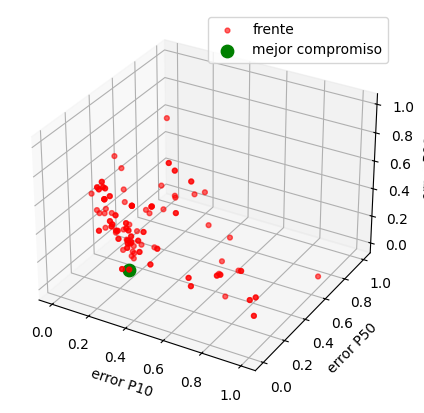

In [14]:
frente = rep + e_file
pop_cost = np.array([p["Cost"] for p in frente]).T          # (3, número de soluciones)
lo, hi = pop_cost.min(axis=1, keepdims=True), pop_cost.max(axis=1, keepdims=True)
OF = (pop_cost - lo) / np.where(hi > lo, hi - lo, 1)
ec_dis = np.sqrt((OF ** 2).sum(axis=0))
b_norm = int(np.argmin(ec_dis))

Cluster_opt = frente[b_norm]["Position"]
Clus_id_opt = medoides(Cluster_opt, X)
print("Realizaciones representativas:", np.sort(Clus_id_opt))
print("Errores de la solución de mejor compromiso [P10, P50, P90] en celdas:", pop_cost[:, b_norm].astype(int))

ax = plt.figure(figsize=(5.5, 5)).add_subplot(projection="3d")
ax.scatter(*OF, c="r", s=12, alpha=0.6, label="frente")
ax.scatter(*OF[:, b_norm], c="g", s=80, label="mejor compromiso")
ax.set_xlabel("error P10"); ax.set_ylabel("error P50"); ax.set_zlabel("error P90"); ax.legend(); plt.show()

## 8. Verificación

Como en la última sección de `Clusterizar_paper_4.m`, se dibujan las delineaciones del ensamble completo (blanco) y las del subconjunto de `k` realizaciones (negro). Si la OCA funcionó, las curvas casi coinciden.

Para saber si la optimización aporta algo, se compara la suma de los tres errores de la solución de mejor compromiso con la de 1 000 subconjuntos de `k` realizaciones elegidos al azar.

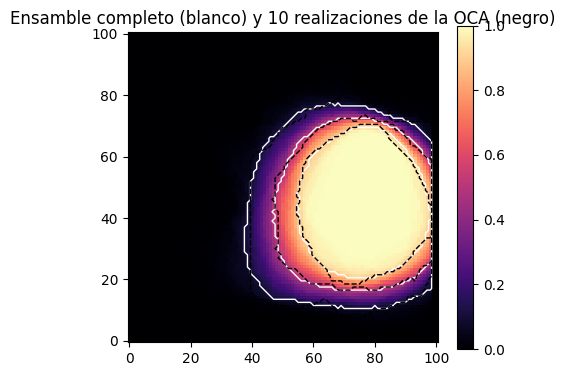

Suma de errores de la OCA 430 celdas. Al azar, mediana 954 y mínimo 524.
Fracción de subconjuntos al azar mejores que la OCA 0.000


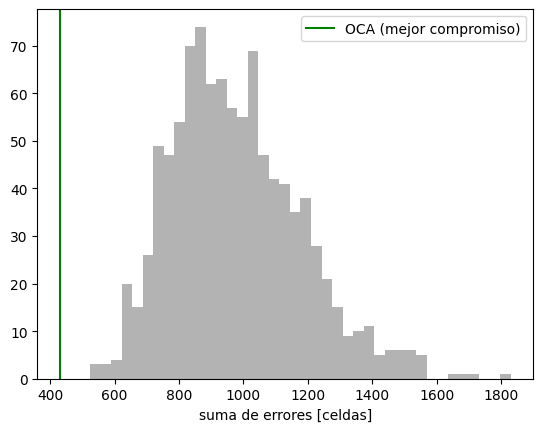

In [15]:
MC_avmap_clus_opt = MC_Steady[Clus_id_opt].sum(axis=0) / k
plt.figure(figsize=(5, 4.2))
plt.imshow(MC_avmap_st.reshape(lado_y, lado_x), origin="lower", cmap="magma"); plt.colorbar()
for u in (0.1, 0.5, 0.9):
    plt.contour((MC_avmap_st >= u).reshape(lado_y, lado_x), levels=[0.5], colors="w", linewidths=1)
    plt.contour((MC_avmap_clus_opt >= u).reshape(lado_y, lado_x), levels=[0.5], colors="k", linewidths=1, linestyles="--")
plt.title(f"Ensamble completo (blanco) y {k} realizaciones de la OCA (negro)"); plt.show()

rng_azar = np.random.default_rng(123)
azar = np.array([ClusteringCost(X[rng_azar.choice(tam, k, replace=False)], X).sum() for _ in range(1000)])
oca = pop_cost[:, b_norm].sum()
print(f"Suma de errores de la OCA {oca:.0f} celdas. Al azar, mediana {np.median(azar):.0f} y mínimo {azar.min():.0f}.")
print(f"Fracción de subconjuntos al azar mejores que la OCA {np.mean(azar <= oca):.3f}")
plt.hist(azar, bins=40, color="0.7"); plt.axvline(oca, color="g", label="OCA (mejor compromiso)")
plt.xlabel("suma de errores [celdas]"); plt.legend(); plt.show()

## 9. Para seguir

* Cambia `k` y observa cómo cambia el error de la solución de mejor compromiso.
* Sube `N_REAL` y compara el tiempo de simulación con el de la optimización.
* Usa los índices `Clus_id_opt` para correr el modelo transitorio de `rrwpt` solo con esas realizaciones y compáralo con el transitorio de todo el ensamble. Esa es la pregunta central del paper.
* Prueba otros buscadores con la misma función de costo, por ejemplo una búsqueda al azar con el mismo número de evaluaciones o una búsqueda voraz que cambie una realización a la vez, y compáralos con OMOPSO.